# Context Overextension Fine-Tuning (COFT) on GPT-2 (A100)

**Paper:** *Train Long, Infer Short: Mitigating Middle-Context Catastrophic Forgetting in LLMs via Context Overextension Fine-Tuning*

This notebook fine-tunes a **real pretrained GPT-2** (via nanoGPT's `from_pretrained`) with COFT, sized for a Colab **A100** GPU. It's meant as a sanity-check run: does PFCM/δ-scheduling/PRGG/CRS actually behave sensibly on a real model, not just a from-scratch baby-GPT.

### What COFT does
- Trains on sequences of length **T + δ** but evaluates at inference length **T**
- Tracks middle-context forgetting via **PFCM** (Positional Forgetting Contrast Metric)
- Applies **PRGG** (Positional Recovery Gradient Gating) to amplify gradient signal from forgotten positions
- Applies **CRS** (Content-conditioned Recency Suppression) to fight U-shaped positional attention bias during training
- Uses an **adaptive δ scheduler** that increases/decreases overextension based on live forgetting signal

### What's different from the T4/baby-GPT version
- Loads **pretrained GPT-2 weights** (`GPT.from_pretrained('gpt2', ...)`) instead of training a small model from scratch
- GPT-2's position embeddings cap `block_size` at **1024**, so `T_INFER + DELTA_MAX <= 1024`
- Fixes a bug in the T4 notebook: on modern PyTorch, nanoGPT's attention uses **Flash Attention**, which has no exposed attention-logit tensor for CRS to bias. The patch below forces the manual attention path on patched layers so CRS can actually inject its bias term.
- Fine-tuning LR is much smaller (`3e-5`-ish) since we're adapting pretrained weights, not training from scratch
- Batch size / block size sized for A100 memory headroom rather than T4

## 0. GPU Check & Setup

In [1]:
import os
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')  # helps with fragmentation
                                                                              # (best set before any CUDA init -- restart runtime if this cell isn't first)
import torch

assert torch.cuda.is_available(), "No GPU found! Change runtime to A100 GPU (Runtime > Change runtime type)."
gpu_name = torch.cuda.get_device_name(0)
vram_gb = torch.cuda.get_device_properties(0).total_memory / 1e9
print(f"GPU: {gpu_name}")
print(f"VRAM: {vram_gb:.1f} GB")
print(f"bf16 supported: {torch.cuda.is_bf16_supported()}")

if "A100" not in gpu_name:
    print("\n⚠️  This wasn't set up on an A100 -- it should still run, but you may need to "
          "shrink BATCH_SIZE in the training-config cell below if you hit OOM.")

GPU: NVIDIA A100-SXM4-40GB
VRAM: 42.4 GB
bf16 supported: True


## 1. Install Dependencies & Clone nanoGPT

In [2]:
!pip install -q torch numpy transformers datasets tiktoken tqdm
!git clone https://github.com/karpathy/nanoGPT.git 2>/dev/null || echo 'Already cloned'
%cd nanoGPT

/content/nanoGPT


## 2. Dataset Preparation

### Dataset options

| Dataset | Why | Size | Time on A100 |
|---|---|---|---|
| **Shakespeare (BPE)** | Fast sanity check, tokenized with the *same GPT-2 BPE* the pretrained model expects | ~300K tokens | ~30s |
| FineWeb-Edu (sample) | Long coherent docs, much more meaningful signal for PFCM/CRS since middle-context forgetting actually shows up | ~25-50M tokens | ~5-10 min |
| OpenWebText | Full GPT-2 training set, standard nanoGPT default | ~9B tokens | ~40 min just to tokenize |

**Default: Shakespeare (BPE)** — good for confirming the COFT mechanics run correctly end-to-end on a real GPT-2. Switch to Option B once you've confirmed things work and want a more meaningful measurement of middle-context forgetting (tiny-Shakespeare is short and repetitive, so PFCM signal will be weak/noisy).

Note: this uses `data/shakespeare/prepare.py` (BPE-tokenized), **not** `data/shakespeare_char` -- GPT-2's embedding table expects GPT-2 BPE token ids, not a custom char vocab.

In [3]:
# ── Option A: Shakespeare, BPE-tokenized (fast, good for verifying COFT mechanics on real GPT-2) ──
!python data/shakespeare/prepare.py
DATASET = 'shakespeare'
print('Shakespeare (BPE) dataset ready.')

train has 301,966 tokens
val has 36,059 tokens
Shakespeare (BPE) dataset ready.


In [4]:
# ── Option B: FineWeb-Edu sample (uncomment for a more meaningful COFT experiment) ──────────
# Streams a sample, tokenizes with GPT-2 BPE. ~5-10 min on A100 for 25M tokens.

# import os, numpy as np
# from datasets import load_dataset
# import tiktoken
#
# os.makedirs('data/fineweb_edu', exist_ok=True)
# enc = tiktoken.get_encoding('gpt2')
#
# ds = load_dataset('HuggingFaceFW/fineweb-edu', name='sample-10BT',
#                   split='train', streaming=True)
#
# all_tokens = []
# for i, ex in enumerate(ds):
#     all_tokens.extend(enc.encode_ordinary(ex['text']))
#     all_tokens.append(enc.eot_token)  # document separator
#     if i >= 24_999:  # ~25k docs, enough for a solid Colab run
#         break
#
# all_tokens = np.array(all_tokens, dtype=np.uint16)
# split = int(len(all_tokens) * 0.9)
# all_tokens[:split].tofile('data/fineweb_edu/train.bin')
# all_tokens[split:].tofile('data/fineweb_edu/val.bin')
# print(f'Saved {len(all_tokens):,} tokens -> train/val split')
# DATASET = 'fineweb_edu'

## 3. COFT Core Implementation

The following cell implements all four COFT components (architecture-agnostic -- unchanged from the baby-GPT version):
1. **PFCM** — measures middle-context perplexity gap
2. **δ Scheduler** — adapts training sequence length
3. **PRGG** — gates gradients by per-position forgetting
4. **CRS** — suppresses recency bias in attention during training

In [5]:
# ─────────────────────────────────────────────────────────────────────────────
# COFT Components
# ─────────────────────────────────────────────────────────────────────────────
import torch
import torch.nn as nn
import torch.nn.functional as F
import math


# ── 1. PFCM: Positional Forgetting Contrast Metric ───────────────────────────
def compute_pfcm(logits: torch.Tensor, targets: torch.Tensor,
                 block_size: int) -> "tuple[float, torch.Tensor]":
    """
    Ft = PPL_middle - (PPL_early + PPL_late) / 2

    Splits the sequence into three equal thirds: early / middle / late.
    Returns (Ft scalar, per_position_nll tensor).
    """
    B, T, V = logits.shape
    third = T // 3

    # Per-position NLL (no reduction)
    per_pos_nll = F.cross_entropy(
        logits.reshape(-1, V), targets.reshape(-1),
        reduction='none'
    ).reshape(B, T)  # (B, T)

    ppl_early  = per_pos_nll[:, :third].mean().item()
    ppl_middle = per_pos_nll[:, third:2*third].mean().item()
    ppl_late   = per_pos_nll[:, 2*third:].mean().item()

    Ft = ppl_middle - (ppl_early + ppl_late) / 2.0
    return Ft, per_pos_nll


# ── 2. Forgetting-Aware δ Scheduler ──────────────────────────────────────────
class DeltaScheduler:
    """
    Tracks Ft history and adjusts δ (context overextension length).
    δ_{t+1} = δ_t + Δ  if forgetting is accelerating
    δ_{t+1} = δ_t - Δ  if retention is stabilising
    """
    def __init__(self, delta_init: int = 64, delta_step: int = 32,
                 delta_min: int = 0, delta_max: int = 512):
        self.delta = delta_init
        self.step  = delta_step
        self.min   = delta_min
        self.max   = delta_max
        self.prev_Ft = None
        self.history = []

    def update(self, Ft: float) -> int:
        self.history.append(Ft)
        if self.prev_Ft is not None:
            if Ft > self.prev_Ft:                         # forgetting accelerating
                self.delta = min(self.delta + self.step, self.max)
            elif Ft < self.prev_Ft:                       # retention stabilising
                self.delta = max(self.delta - self.step, self.min)
        self.prev_Ft = Ft
        return self.delta


# ── 3. PRGG: Positional Recovery Gradient Gating ─────────────────────────────
class PRGGHook:
    """
    Registers backward hooks on the token embedding weight to scale
    gradients by per-position forgetting signal.

    g_i = σ(α * F_i / F̄)

    Middle positions with high F_i get larger effective gradient headroom;
    edge positions are suppressed.
    """
    def __init__(self, alpha: float = 2.0):
        self.alpha = alpha
        self.per_pos_nll = None
        self._handle = None

    def register(self, param: nn.Parameter):
        """Attach to any parameter whose grad we want to gate."""
        def hook(grad):
            if self.per_pos_nll is None:
                return grad
            F_i  = self.per_pos_nll.mean(0)            # (T,)
            F_bar = F_i.mean()
            gate = torch.sigmoid(self.alpha * F_i / (F_bar + 1e-8))  # (T,)
            # Average gate across positions as a scalar multiplier
            # (full per-token gating would require token-level grad decomp)
            scalar_gate = gate.mean()
            return grad * scalar_gate
        self._handle = param.register_hook(hook)

    def update_forgetting(self, per_pos_nll: torch.Tensor):
        self.per_pos_nll = per_pos_nll.detach()

    def remove(self):
        if self._handle:
            self._handle.remove()


# ── 4. CRS: Content-conditioned Recency Suppression ───────────────────────────
class CRSMixin:
    """
    Mixin to add to a CausalSelfAttention layer.
    Modifies attention logits during TRAINING only:

    ã_{l,h,i,j} = a_{l,h,i,j} + I[j ∈ M] · (l/L) · λ · Ft · cos(q_i, k_j)

    Removed at inference (Ft set to 0 or crs_enabled=False).
    """
    def __init__(self):
        self.crs_enabled  = True   # set False at inference
        self.crs_lambda   = 0.5    # hyperparameter λ
        self.crs_Ft       = 0.0    # updated each step from PFCM
        self.crs_layer_id = 0      # l  (set after instantiation)
        self.crs_n_layers = 1      # L  (set after instantiation)

    def apply_crs(self, att: torch.Tensor,
                  q: torch.Tensor, k: torch.Tensor) -> torch.Tensor:
        """
        att : (B, nh, T, T) raw attention logits
        q   : (B, nh, T, hs)
        k   : (B, nh, T, hs)
        """
        if not self.crs_enabled or self.crs_Ft <= 0:
            return att

        B, nh, T, hs = q.shape
        third = T // 3
        middle_mask = torch.zeros(T, dtype=torch.bool, device=att.device)
        middle_mask[third:2*third] = True   # j ∈ M

        # Cosine similarity between every query and every key (content gate)
        q_norm = F.normalize(q, dim=-1)           # (B, nh, T, hs)
        k_norm = F.normalize(k, dim=-1)           # (B, nh, T, hs)
        cos_sim = torch.einsum('bnqd,bnkd->bnqk', q_norm, k_norm)  # (B,nh,T,T)

        depth_scale = (self.crs_layer_id + 1) / self.crs_n_layers   # l/L
        bias = (middle_mask[None, None, None, :].float()             # (1,1,1,T)
                * depth_scale
                * self.crs_lambda
                * self.crs_Ft
                * cos_sim)

        return att + bias


print('COFT components defined ✓')

COFT components defined ✓


## 4. Patch GPT-2 with CRS

⚠️ **Fix vs. the T4/baby-GPT notebook:** nanoGPT's `CausalSelfAttention` uses Flash Attention whenever `torch.nn.functional.scaled_dot_product_attention` is available (true on any Colab A100 runtime), and never materializes an explicit attention-logit tensor in that path -- so there's nothing for CRS to add its bias to. The patch below forces the manual (non-flash) attention path **only on the patched layers**, and registers the causal mask buffer if it isn't already there, so CRS's bias term actually reaches the softmax.

In [6]:
import sys
sys.path.insert(0, '.')  # make nanoGPT importable

from model import GPT, GPTConfig, CausalSelfAttention
import types


def _coft_forward(self, x):
    """
    Patched CausalSelfAttention.forward with CRS applied.
    Always uses the manual (non-flash) attention path, since CRS needs
    to add a bias directly onto the pre-softmax attention logits.
    """
    B, T, C = x.size()
    # QKV projection
    q, k, v = self.c_attn(x).split(self.n_embd, dim=2)
    nh, hs = self.n_head, C // self.n_head
    q = q.view(B, T, nh, hs).transpose(1, 2)   # (B, nh, T, hs)
    k = k.view(B, T, nh, hs).transpose(1, 2)
    v = v.view(B, T, nh, hs).transpose(1, 2)

    # Standard scaled dot-product attention logits
    att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(hs))
    att = att.masked_fill(
        self.bias[:, :, :T, :T] == 0, float('-inf')
    )

    # ── CRS injection ─────────────────────────────────────────────────────
    if hasattr(self, 'crs_enabled') and self.crs_enabled and self.training:
        att = self.apply_crs(att, q, k)
    # ──────────────────────────────────────────────────────────────────────

    att = F.softmax(att, dim=-1)
    att = self.attn_dropout(att)
    y   = att @ v
    y   = y.transpose(1, 2).contiguous().view(B, T, C)
    y   = self.resid_dropout(self.c_proj(y))
    return y


def patch_model_with_crs(model: GPT):
    """Inject CRS into every attention layer of a (pretrained) nanoGPT model."""
    n_layers = len(model.transformer.h)
    block_size = model.config.block_size
    dev = next(model.parameters()).device

    for layer_id, block in enumerate(model.transformer.h):
        attn = block.attn
        attn.flash = False  # force the manual path so CRS can touch the logits
        if not hasattr(attn, 'bias'):
            causal_mask = torch.tril(torch.ones(block_size, block_size, device=dev))
            attn.register_buffer('bias', causal_mask.view(1, 1, block_size, block_size))
        # Mix in CRS state
        attn.crs_enabled  = True
        attn.crs_lambda   = 0.5
        attn.crs_Ft       = 0.0
        attn.crs_layer_id = layer_id
        attn.crs_n_layers = n_layers
        attn.apply_crs    = types.MethodType(CRSMixin.apply_crs, attn)
        # Patch forward
        attn.forward = types.MethodType(_coft_forward, attn)
    print(f'CRS patched into {n_layers} attention layers (flash attention disabled on these layers) ✓')
    return model


def set_crs_ft(model: GPT, Ft: float):
    """Broadcast current PFCM value to all attention layers."""
    for block in model.transformer.h:
        block.attn.crs_Ft = Ft


def disable_crs(model: GPT):
    """Disable CRS for inference -- zero overhead beyond the non-flash path."""
    for block in model.transformer.h:
        block.attn.crs_enabled = False


print('CRS patch functions defined ✓')

CRS patch functions defined ✓


## 5. COFT Training Configuration (A100-sized)

Key differences from the T4/baby-GPT config:
- `MODEL_TYPE = 'gpt2'` loads the real 124M-parameter pretrained checkpoint (swap to `'gpt2-medium'`/`'gpt2-large'` if you want to push the A100 harder -- 350M and 774M both fit comfortably)
- `T_INFER + DELTA_MAX` is capped at **1024** (GPT-2's fixed position-embedding size)
- `LR` is small (`3e-5`) -- this is fine-tuning pretrained weights, not training from scratch, so a from-scratch-sized LR (`1e-3`) would wreck the pretrained representations in a handful of steps
- `MAX_ITERS` is small (this is a sanity-check run) -- bump it up once you've confirmed everything runs cleanly

In [7]:
import os, math, time, pickle
import numpy as np
import torch
from contextlib import nullcontext
from model import GPT, GPTConfig

# ── Training hyperparams ──────────────────────────────────────────────────────
MODEL_TYPE      = 'gpt2'                # 124M pretrained GPT-2 ('gpt2-medium'/'large'/'xl' also fit on A100)
DATASET         = 'shakespeare'         # matches the BPE-tokenized dataset prepared above

T_INFER         = 512                   # inference context length (T)
DELTA_INIT      = 128                   # initial overextension δ
DELTA_STEP      = 64                    # δ adjustment step size
DELTA_MAX       = 256                   # lowered from 512 -- caps peak block size (and CRS's O(T^2)
                                         # tensors) at T_INFER+256 instead of the full 1024

assert T_INFER + DELTA_MAX <= 1024, "T_INFER + DELTA_MAX can't exceed GPT-2's 1024 position embeddings"

BATCH_SIZE      = 8                     # lowered from 16 -- CRS materializes full (B,nh,T,T) attn
                                         # AND cosine-sim tensors (no flash-attention fusion), so
                                         # memory grows quadratically with T as δ climbs toward DELTA_MAX
GRAD_ACCUM      = 4                     # effective batch = 32 (unchanged)
MAX_ITERS       = 300                   # sanity-check run -- raise this for a real experiment
EVAL_INTERVAL   = 25
EVAL_ITERS      = 20

LR              = 3e-5                  # small: fine-tuning pretrained weights, not training from scratch
MIN_LR          = 3e-6
WARMUP_ITERS    = 20
WEIGHT_DECAY    = 0.1
GRAD_CLIP       = 1.0
DTYPE           = 'bfloat16' if torch.cuda.is_bf16_supported() else 'float16'

device    = 'cuda'
ptdtype   = {'float32': torch.float32,
             'bfloat16': torch.bfloat16,
             'float16': torch.float16}[DTYPE]
ctx       = torch.amp.autocast(device_type='cuda', dtype=ptdtype)
scaler    = torch.cuda.amp.GradScaler(enabled=(DTYPE == 'float16'))  # no-op under bf16

print(f'Device : {device}')
print(f'Dtype  : {DTYPE}')
print(f'Model  : {MODEL_TYPE}')
print(f'T_infer: {T_INFER}  δ_init: {DELTA_INIT}  max block: {T_INFER + DELTA_MAX}')

Device : cuda
Dtype  : bfloat16
Model  : gpt2
T_infer: 512  δ_init: 128  max block: 768


/tmp/ipykernel_5991/2479450261.py:39: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler    = torch.cuda.amp.GradScaler(enabled=(DTYPE == 'float16'))  # no-op under bf16


## 6. Data Loader

In [8]:
data_dir = os.path.join('data', DATASET)
meta_path = os.path.join(data_dir, 'meta.pkl')  # only exists for char-level datasets; BPE datasets won't have this

train_data = np.memmap(os.path.join(data_dir, 'train.bin'), dtype=np.uint16, mode='r')
val_data   = np.memmap(os.path.join(data_dir, 'val.bin'),   dtype=np.uint16, mode='r')
print(f'Train tokens: {len(train_data):,}  Val tokens: {len(val_data):,}')


def get_batch(split: str, block_size: int):
    """Sample a batch of (x, y) with the given block_size."""
    data = train_data if split == 'train' else val_data
    ix   = torch.randint(len(data) - block_size, (BATCH_SIZE,))
    x    = torch.stack([torch.from_numpy(data[i  :i+block_size  ].astype(np.int64)) for i in ix])
    y    = torch.stack([torch.from_numpy(data[i+1:i+block_size+1].astype(np.int64)) for i in ix])
    return x.to(device), y.to(device)

print('Data loader ready ✓')

Train tokens: 301,966  Val tokens: 36,059
Data loader ready ✓


## 7. Load Pretrained GPT-2 + Patch with CRS

This pulls real GPT-2 weights from HuggingFace via nanoGPT's `from_pretrained`, which always forces `vocab_size=50257`, `block_size=1024`, `bias=True` to match the original checkpoint.

In [9]:
model = GPT.from_pretrained(MODEL_TYPE, dict(dropout=0.1))
model.to(device)
model = patch_model_with_crs(model)

num_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f'Model params: {num_params:.2f}M')
print(f'Block size (GPT-2 position embedding limit): {model.config.block_size}')

loading weights from pretrained gpt: gpt2
forcing vocab_size=50257, block_size=1024, bias=True
overriding dropout rate to 0.1
number of parameters: 123.65M


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

CRS patched into 12 attention layers (flash attention disabled on these layers) ✓
Model params: 124.44M
Block size (GPT-2 position embedding limit): 1024


## 8. Optimizer & PRGG Setup

In [10]:
optimizer = model.configure_optimizers(WEIGHT_DECAY, LR, (0.9, 0.95), device)

# PRGG hook on the token embedding (primary gradient entry point)
prgg_hook = PRGGHook(alpha=2.0)
prgg_hook.register(model.transformer.wte.weight)

# δ scheduler
delta_sched = DeltaScheduler(
    delta_init=DELTA_INIT,
    delta_step=DELTA_STEP,
    delta_max=DELTA_MAX
)


def get_lr(it: int) -> float:
    """Cosine decay with linear warmup."""
    if it < WARMUP_ITERS:
        return LR * it / WARMUP_ITERS
    if it > MAX_ITERS:
        return MIN_LR
    decay_ratio = (it - WARMUP_ITERS) / (MAX_ITERS - WARMUP_ITERS)
    coeff = 0.5 * (1.0 + math.cos(math.pi * decay_ratio))
    return MIN_LR + coeff * (LR - MIN_LR)

print('Optimizer & hooks ready ✓')

num decayed parameter tensors: 50, with 124,318,464 parameters
num non-decayed parameter tensors: 98, with 121,344 parameters
using fused AdamW: True
Optimizer & hooks ready ✓


## 9. Evaluation with PFCM

In [11]:
@torch.no_grad()
def evaluate(model: GPT, block_size: int) -> dict:
    """
    Returns val loss and PFCM computed at INFERENCE length T_INFER.
    CRS is disabled for val -- only standard (masked) attention.
    """
    model.eval()
    disable_crs(model)   # ← CRS off at eval

    losses, Fts = [], []
    for _ in range(EVAL_ITERS):
        # Always evaluate at T_INFER (not T+δ)
        x, y = get_batch('val', T_INFER)
        with ctx:
            logits, loss = model(x, y)
        losses.append(loss.item())
        Ft, _ = compute_pfcm(logits, y, T_INFER)
        Fts.append(Ft)

    # Re-enable CRS for next training iteration
    for block in model.transformer.h:
        block.attn.crs_enabled = True
    model.train()

    return {
        'val_loss': float(np.mean(losses)),
        'pfcm'    : float(np.mean(Fts)),
    }

print('Evaluation function ready ✓')

Evaluation function ready ✓


## 10. COFT Training Loop

In [12]:
log = {'iter': [], 'train_loss': [], 'val_loss': [], 'pfcm': [], 'delta': []}

model.train()
t0 = time.time()
Ft_current = 0.0

for iteration in range(1, MAX_ITERS + 1):

    # ── Update LR ────────────────────────────────────────────────────────
    lr = get_lr(iteration)
    for pg in optimizer.param_groups:
        pg['lr'] = lr

    # ── Get current training block size = T + δ ──────────────────────────
    delta = delta_sched.delta
    train_block = T_INFER + delta

    # ── Broadcast Ft to CRS layers ───────────────────────────────────────
    set_crs_ft(model, Ft_current)

    # ── Gradient accumulation ─────────────────────────────────────────────
    optimizer.zero_grad(set_to_none=True)
    total_loss = 0.0

    for micro_step in range(GRAD_ACCUM):
        x, y = get_batch('train', train_block)
        with ctx:
            logits, loss = model(x, y)
            loss = loss / GRAD_ACCUM

        total_loss += loss.item()

        # Update PRGG with latest per-position forgetting, and reuse the same
        # (detached) per-position NLL for Ft_current below -- avoids a second,
        # redundant full forward pass over (B, T, vocab_size) just to recompute it.
        Ft_current, per_pos_nll = compute_pfcm(logits.detach(), y, train_block)
        prgg_hook.update_forgetting(per_pos_nll)

        scaler.scale(loss).backward()

    # ── Gradient clip & step ─────────────────────────────────────────────
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
    scaler.step(optimizer)
    scaler.update()

    # ── Update δ scheduler ───────────────────────────────────────────────
    delta = delta_sched.update(Ft_current)

    # ── Periodic evaluation ──────────────────────────────────────────────
    if iteration % EVAL_INTERVAL == 0 or iteration == 1:
        metrics = evaluate(model, T_INFER)
        dt = time.time() - t0

        log['iter'].append(iteration)
        log['train_loss'].append(total_loss)
        log['val_loss'].append(metrics['val_loss'])
        log['pfcm'].append(metrics['pfcm'])
        log['delta'].append(delta)

        print(f"iter {iteration:5d} | "
              f"train_loss {total_loss:.4f} | "
              f"val_loss {metrics['val_loss']:.4f} | "
              f"PFCM {metrics['pfcm']:+.4f} | "
              f"δ {delta:3d} | "
              f"{dt:.1f}s")

        t0 = time.time()

print('\nTraining complete ✓')

iter     1 | train_loss 4.3429 | val_loss 4.0323 | PFCM -0.2035 | δ 128 | 1.9s
iter    25 | train_loss 3.7489 | val_loss 3.4282 | PFCM -0.1391 | δ 256 | 11.9s
iter    50 | train_loss 3.6173 | val_loss 3.3847 | PFCM -0.0887 | δ   0 | 10.4s
iter    75 | train_loss 3.5590 | val_loss 3.2994 | PFCM -0.1145 | δ 128 | 9.9s
iter   100 | train_loss 3.3514 | val_loss 3.3341 | PFCM -0.1164 | δ  64 | 9.5s
iter   125 | train_loss 3.4963 | val_loss 3.3137 | PFCM -0.1324 | δ 192 | 10.7s
iter   150 | train_loss 3.3817 | val_loss 3.3199 | PFCM -0.0508 | δ  64 | 11.5s
iter   175 | train_loss 3.3738 | val_loss 3.3351 | PFCM -0.0348 | δ 256 | 9.8s
iter   200 | train_loss 3.3122 | val_loss 3.2678 | PFCM -0.1250 | δ 192 | 12.3s
iter   225 | train_loss 3.2505 | val_loss 3.2602 | PFCM -0.0727 | δ 192 | 12.2s
iter   250 | train_loss 3.3792 | val_loss 3.2607 | PFCM -0.1414 | δ 192 | 12.3s
iter   275 | train_loss 3.2788 | val_loss 3.2493 | PFCM -0.0969 | δ  64 | 12.1s
iter   300 | train_loss 3.3318 | val_loss 3.

## 11. Results Visualisation

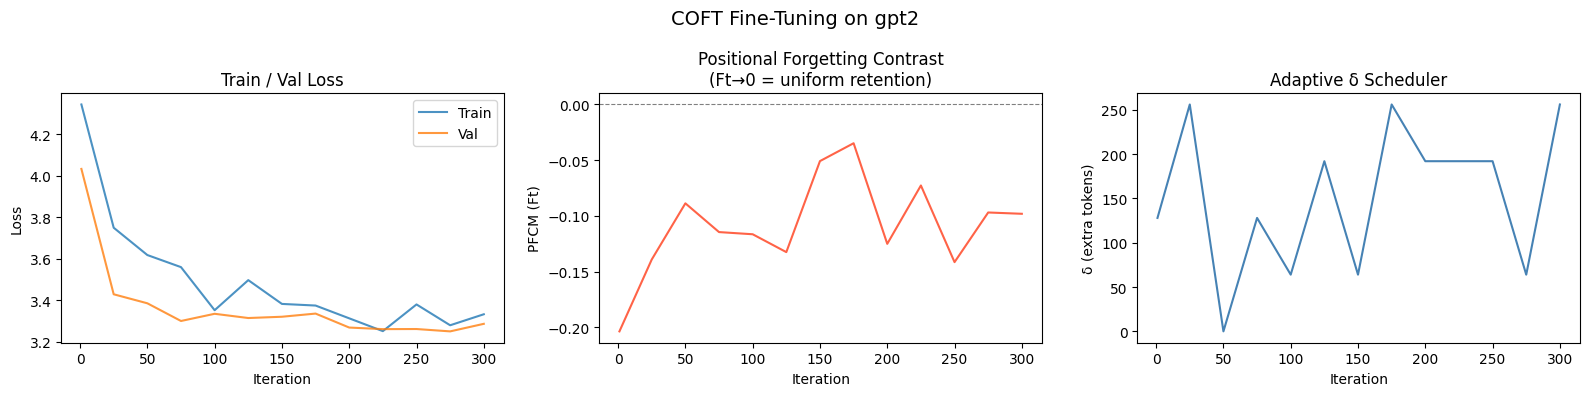

Plot saved to coft_results.png


In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle(f'COFT Fine-Tuning on {MODEL_TYPE}', fontsize=14)

axes[0].plot(log['iter'], log['train_loss'], label='Train', alpha=0.8)
axes[0].plot(log['iter'], log['val_loss'],   label='Val',   alpha=0.8)
axes[0].set_xlabel('Iteration'); axes[0].set_ylabel('Loss')
axes[0].set_title('Train / Val Loss'); axes[0].legend()

axes[1].plot(log['iter'], log['pfcm'], color='tomato')
axes[1].axhline(0, linestyle='--', color='gray', linewidth=0.8)
axes[1].set_xlabel('Iteration'); axes[1].set_ylabel('PFCM (Ft)')
axes[1].set_title('Positional Forgetting Contrast\n(Ft→0 = uniform retention)')

axes[2].plot(log['iter'], log['delta'], color='steelblue')
axes[2].set_xlabel('Iteration'); axes[2].set_ylabel('δ (extra tokens)')
axes[2].set_title('Adaptive δ Scheduler')

plt.tight_layout()
plt.savefig('coft_results.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot saved to coft_results.png')

## 12. Save Checkpoint & Inference

In [14]:
# Save model checkpoint
ckpt = {
    'model'     : model.state_dict(),
    'config'    : model.config,
    'log'       : log,
    'T_infer'   : T_INFER,
    'delta_hist': delta_sched.history,
}
torch.save(ckpt, 'coft_gpt2_checkpoint.pt')
print('Checkpoint saved to coft_gpt2_checkpoint.pt')

Checkpoint saved to coft_gpt2_checkpoint.pt


In [15]:
# ── Inference: CRS disabled automatically ────────────────────────────────────
model.eval()
disable_crs(model)   # no CRS overhead at inference

import tiktoken
enc = tiktoken.get_encoding('gpt2')
encode = enc.encode
decode = enc.decode

prompt = "The quick brown fox"
start_ids = encode(prompt)
x = torch.tensor(start_ids, dtype=torch.long, device=device).unsqueeze(0)

with torch.no_grad(), ctx:
    y = model.generate(x, max_new_tokens=100, temperature=0.8, top_k=40)

print(decode(y[0].tolist()))

The quick brown fox of the ground, a creature of the earth, and of the sea, hath a fiery appetite.

MENENIUS:
And, madam, I think I shall have thy father in the field of battle.

HENRY BOLINGBROKE:
And come, madam, here to ask your opinion.

MENENIUS:
Is it lawful for the king to kill a man named Hoster?

MENENIUS:


## 13. Ablation Utility

Run this cell to compare **COFT-finetuned GPT-2 vs. a plain fine-tuned GPT-2 baseline** (same pretrained starting point, same LR/steps, no overextension, no PRGG, no CRS -- standard flash attention, so this also runs faster).

In [16]:
# ── Baseline: plain fine-tune of the same pretrained GPT-2, no COFT ──────────
baseline_model = GPT.from_pretrained(MODEL_TYPE, dict(dropout=0.1)).to(device)
baseline_optim = baseline_model.configure_optimizers(WEIGHT_DECAY, LR, (0.9, 0.95), device)

baseline_log = {'iter': [], 'val_loss': [], 'pfcm': []}
baseline_model.train()

ABLATION_ITERS = MAX_ITERS

for iteration in range(1, ABLATION_ITERS + 1):
    lr = get_lr(iteration)
    for pg in baseline_optim.param_groups:
        pg['lr'] = lr

    baseline_optim.zero_grad(set_to_none=True)
    for _ in range(GRAD_ACCUM):
        x, y = get_batch('train', T_INFER)   # standard block size, no overextension
        with ctx:
            logits, loss = baseline_model(x, y)
            (loss / GRAD_ACCUM).backward()
    torch.nn.utils.clip_grad_norm_(baseline_model.parameters(), GRAD_CLIP)
    baseline_optim.step()

    if iteration % EVAL_INTERVAL == 0:
        baseline_model.eval()
        bl_losses, bl_Fts = [], []
        with torch.no_grad():
            for _ in range(EVAL_ITERS):
                bx, by = get_batch('val', T_INFER)
                with ctx:
                    bl_logits, bl_loss = baseline_model(bx, by)
                bl_losses.append(bl_loss.item())
                Ft_b, _ = compute_pfcm(bl_logits, by, T_INFER)
                bl_Fts.append(Ft_b)
        baseline_model.train()
        baseline_log['iter'].append(iteration)
        baseline_log['val_loss'].append(float(np.mean(bl_losses)))
        baseline_log['pfcm'].append(float(np.mean(bl_Fts)))
        print(f"[Baseline] iter {iteration} | val_loss {np.mean(bl_losses):.4f} | PFCM {np.mean(bl_Fts):+.4f}")

# Compare PFCM
coft_pfcm_end     = log['pfcm'][-1] if log['pfcm'] else float('nan')
baseline_pfcm_end = baseline_log['pfcm'][-1] if baseline_log['pfcm'] else float('nan')
print(f'\nFinal PFCM -- COFT: {coft_pfcm_end:+.4f}  |  Baseline: {baseline_pfcm_end:+.4f}')
print('Lower (closer to 0) = more uniform retention across context positions.')

loading weights from pretrained gpt: gpt2
forcing vocab_size=50257, block_size=1024, bias=True
overriding dropout rate to 0.1
number of parameters: 123.65M


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

num decayed parameter tensors: 50, with 124,318,464 parameters
num non-decayed parameter tensors: 98, with 121,344 parameters
using fused AdamW: True
[Baseline] iter 25 | val_loss 3.4936 | PFCM -0.1211
[Baseline] iter 50 | val_loss 3.4108 | PFCM -0.1629
[Baseline] iter 75 | val_loss 3.2848 | PFCM -0.1145
[Baseline] iter 100 | val_loss 3.3250 | PFCM -0.0609
[Baseline] iter 125 | val_loss 3.3543 | PFCM -0.1273
[Baseline] iter 150 | val_loss 3.2707 | PFCM -0.0738
[Baseline] iter 175 | val_loss 3.3139 | PFCM -0.1043
[Baseline] iter 200 | val_loss 3.3147 | PFCM -0.0992
[Baseline] iter 225 | val_loss 3.2730 | PFCM -0.1367
[Baseline] iter 250 | val_loss 3.2932 | PFCM -0.0887
[Baseline] iter 275 | val_loss 3.2639 | PFCM -0.1309
[Baseline] iter 300 | val_loss 3.3023 | PFCM -0.0898

Final PFCM -- COFT: -0.0980  |  Baseline: -0.0898
Lower (closer to 0) = more uniform retention across context positions.


## Notes & Next Steps

### A100 memory budget (gpt2, 124M)
| T_INFER | δ_max | Batch | Effective block | VRAM est. |
|---|---|---|---|---|
| 512 | 512 | 16 | 1024 | ~20-25 GB ✅ (40GB A100) |
| 384 | 384 | 24 | 768  | ~15-18 GB ✅ |
| 256 | 256 | 32 | 512  | ~10-12 GB ✅ |

Larger `gpt2-medium` (350M) or `gpt2-large` (774M) will roughly 3-6x these numbers -- drop `BATCH_SIZE` accordingly if you switch `MODEL_TYPE`.

### This is a sanity-check run, not a real experiment
`MAX_ITERS = 300` on tiny-Shakespeare is enough to confirm the mechanics (PFCM computation, δ scheduling, PRGG gradient gating, CRS bias injection) all run without errors and produce sane-looking numbers. It is **not** enough data or steps to draw real conclusions about whether COFT helps -- for that, switch to Option B (FineWeb-Edu) or C (OpenWebText) in the dataset cell and raise `MAX_ITERS` substantially (thousands, not hundreds).

### Why flash attention is disabled on patched layers
CRS needs to add a bias term directly to pre-softmax attention logits, which Flash Attention kernels don't expose. This means COFT-patched layers run somewhat slower than plain GPT-2 fine-tuning (which is why the baseline ablation above uses an unpatched model with flash attention still on -- that's also the fairer comparison against "how nanoGPT fine-tunes GPT-2 out of the box").

### Key metrics to track
- **PFCM (Ft)**: should trend toward 0 with COFT vs. remaining positive/growing with the baseline
- **Val loss**: should be comparable to or better than the baseline at the same iteration count
- **δ**: watch whether the scheduler actually moves off `DELTA_INIT` -- if it's pinned at the min or max the whole run, `DELTA_STEP`/`DELTA_MAX` probably need tuning for your dataset